Clustering Methods

Memuat Dataset dan Menyiapkan Fitur

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

data = pd.read_csv("data/WineQT.csv")
print("Ukuran dataset:", data.shape)
display(data.head())

Ukuran dataset: (1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [2]:
#Kolom Id dan quality tidak digunakan sebagai fitur clustering
X = data.drop(columns=["Id", "quality"])

print("Jumlah fitur:", X.shape[1])
display(X.describe().T)

Jumlah fitur: 11


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1143.0,8.311111,1.747595,4.60000,7.10000,7.90000,9.100000,15.90000
volatile acidity,1143.0,0.531339,0.179633,0.12000,0.39250,0.52000,0.640000,1.58000
citric acid,1143.0,0.268364,0.196686,0.00000,0.09000,0.25000,0.420000,1.00000
residual sugar,1143.0,2.532152,1.355917,0.90000,1.90000,2.20000,2.600000,15.50000
chlorides,1143.0,0.086933,0.047267,0.01200,0.07000,0.07900,0.090000,0.61100
free sulfur dioxide,1143.0,15.615486,10.250486,1.00000,7.00000,13.00000,21.000000,68.00000
total sulfur dioxide,1143.0,45.914698,32.782130,6.00000,21.00000,37.00000,61.000000,289.00000
density,1143.0,0.996730,0.001925,0.99007,0.99557,0.99668,0.997845,1.00369
pH,1143.0,3.311015,0.156664,2.74000,3.20500,3.31000,3.400000,4.01000
sulphates,1143.0,0.657708,0.170399,0.33000,0.55000,0.62000,0.730000,2.00000


Scaling Fitur

K-Means dan Agglomerative Clustering menggunakan perhitungan jarak. Karena skala setiap fitur kimia berbeda, fitur perlu distandardisasi terlebih dahulu.

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(X_scaled, columns=X.columns)
display(X_scaled.head())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,-0.521580,0.939332,-1.365027,-0.466421,-0.231395,-0.450467,-0.363610,0.555854,1.270695,-0.573658,-0.963382
1,-0.292593,1.941813,-1.365027,0.050060,0.234247,0.915920,0.643477,0.036165,-0.708928,0.130881,-0.593601
2,-0.292593,1.273492,-1.161568,-0.171289,0.107253,-0.060071,0.246745,0.140103,-0.325775,-0.045254,-0.593601
3,1.653789,-1.399789,1.483400,-0.466421,-0.252560,0.135127,0.429852,0.659792,-0.964363,-0.456235,-0.593601
4,-0.521580,0.939332,-1.365027,-0.466421,-0.231395,-0.450467,-0.363610,0.555854,1.270695,-0.573658,-0.963382


K-Means Clustering

K-Means membagi data menjadi sejumlah cluster berdasarkan kedekatan jarak terhadap pusat cluster (*centroid*). Contoh berikut membagi data menjadi 3 cluster.

In [4]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
data["kmeans_cluster"] = kmeans.fit_predict(X_scaled)

print(data["kmeans_cluster"].value_counts().sort_index())

kmeans_cluster
0    523
1    271
2    349
Name: count, dtype: int64


In [5]:
# Melihat rata-rata kualitas pada setiap cluster
cluster_quality = data.groupby("kmeans_cluster")["quality"].agg(
    ["count", "mean", "median"]
)
display(cluster_quality)

,count,mean,median
kmeans_cluster,,,
0,523,5.586998,6.0
1,271,5.354244,5.0
2,349,5.997135,6.0


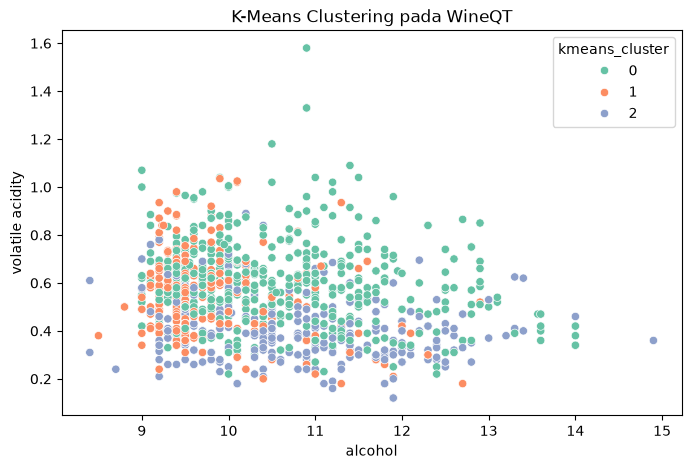

In [6]:
# Visualisasi dua fitur sebagai gambaran cluster
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=data,
    x="alcohol",
    y="volatile acidity",
    hue="kmeans_cluster",
    palette="Set2"
)
plt.title("K-Means Clustering pada WineQT")
plt.show()

Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method membandingkan nilai *inertia* dari beberapa jumlah cluster. Titik ketika penurunan inertia mulai melambat dapat menjadi kandidat jumlah cluster.

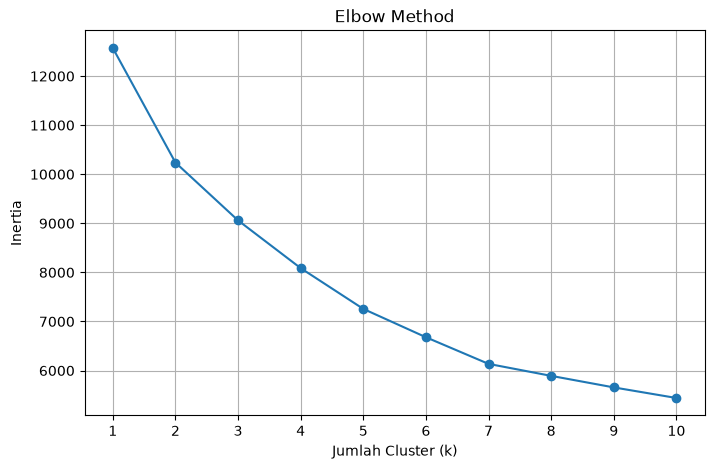

In [7]:
inertias = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

Tidak selalu ada satu titik siku yang sangat jelas. Pilih jumlah cluster dengan mempertimbangkan bentuk grafik dan tujuan analisis.

Agglomerative Clustering

Agglomerative Clustering adalah metode *hierarchical clustering* yang dimulai dengan setiap data sebagai cluster tersendiri, lalu menggabungkan cluster yang paling dekat secara bertahap.

Di bawah ini digunakan 3 cluster dengan linkage `ward`.

In [8]:
agg = AgglomerativeClustering(n_clusters=3, linkage="ward")
data["agg_cluster"] = agg.fit_predict(X_scaled)

display(
    data.groupby("agg_cluster")["quality"].agg(
        jumlah="count",
        rata_rata_kualitas="mean",
        median_kualitas="median"
    )
)

,jumlah,rata_rata_kualitas,median_kualitas
agg_cluster,,,
0,235,5.970213,6.0
1,588,5.702381,6.0
2,320,5.343750,5.0


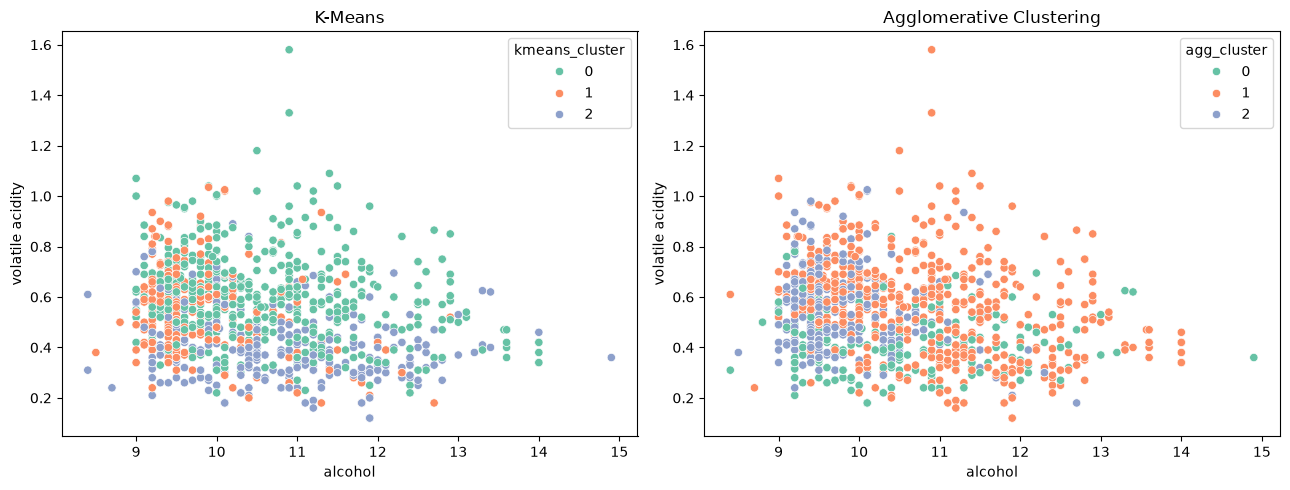

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=data, x="alcohol", y="volatile acidity",
    hue="kmeans_cluster", palette="Set2", ax=axes[0]
)
axes[0].set_title("K-Means")

sns.scatterplot(
    data=data, x="alcohol", y="volatile acidity",
    hue="agg_cluster", palette="Set2", ax=axes[1]
)
axes[1].set_title("Agglomerative Clustering")

plt.tight_layout()
plt.show()

Dendrogram

Dendrogram memperlihatkan proses penggabungan cluster dalam hierarchical clustering. Agar grafik tetap terbaca, contoh ini menggunakan sampel 100 baris.

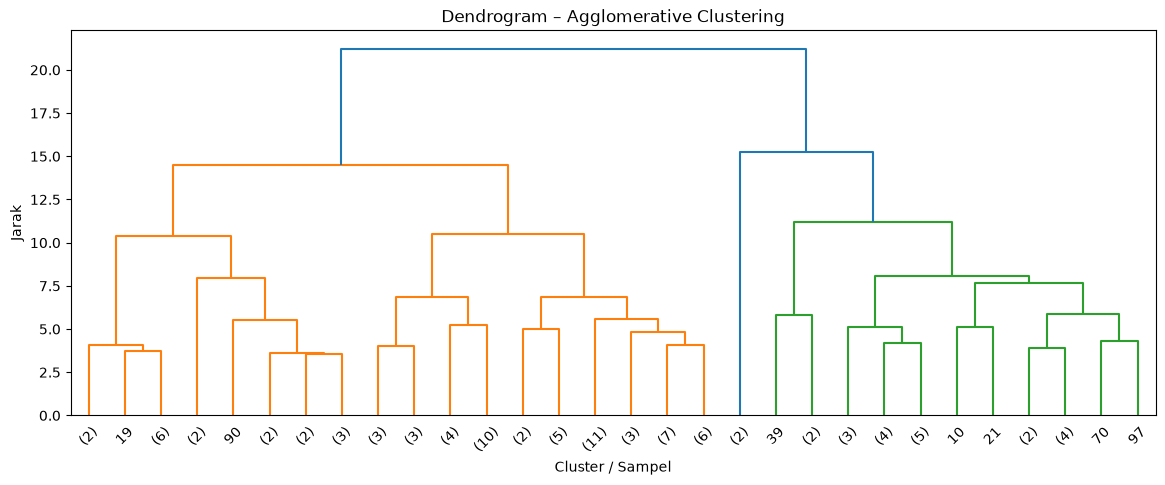

In [10]:
from scipy.cluster.hierarchy import linkage, dendrogram

sample = X_scaled.sample(n=100, random_state=42)
Z = linkage(sample, method="ward")

plt.figure(figsize=(14, 5))
dendrogram(Z, truncate_mode="lastp", p=30)
plt.title("Dendrogram – Agglomerative Clustering")
plt.xlabel("Cluster / Sampel")
plt.ylabel("Jarak")
plt.show()

Evaluasi dan Perbandingan Cluster

Silhouette Score mengukur seberapa dekat sebuah data dengan cluster-nya dibandingkan dengan cluster lain. Nilai yang lebih tinggi umumnya menunjukkan pemisahan cluster yang lebih baik.

In [11]:
score_kmeans = silhouette_score(X_scaled, data["kmeans_cluster"])
score_agg = silhouette_score(X_scaled, data["agg_cluster"])

comparison = pd.DataFrame({
    "Metode": ["K-Means", "Agglomerative"],
    "Silhouette Score": [score_kmeans, score_agg]
})
display(comparison)

,Metode,Silhouette Score
0,K-Means,0.182872
1,Agglomerative,0.129576


Clustering sebagai Feature Engineering (Pengembangan)

Hasil cluster dapat ditambahkan sebagai fitur baru untuk membantu model klasifikasi. Contoh ini memprediksi apakah `quality` lebih dari 7, mengikuti ide pada lab asli.

Karena kelas `quality > 7` dapat berjumlah sedikit, hasil ROC-AUC perlu ditafsirkan dengan hati-hati.

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.cluster import KMeans

# Target biner: 1 jika quality > 7, selain itu 0
y = (data["quality"] > 7).astype(int)

# Gunakan fitur kimia yang sudah distandardisasi
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.25, random_state=42, stratify=y
)

# Model dasar tanpa fitur cluster
base_model = LogisticRegression(max_iter=1000)
base_model.fit(X_train, y_train)
base_prob = base_model.predict_proba(X_test)[:, 1]
base_auc = roc_auc_score(y_test, base_prob)

# Bentuk cluster hanya dari data training, lalu prediksi cluster data test
km_feature = KMeans(n_clusters=3, random_state=42, n_init=10)
train_cluster = km_feature.fit_predict(X_train)
test_cluster = km_feature.predict(X_test)

# One-hot encoding label cluster
train_cluster_df = pd.get_dummies(train_cluster, prefix="cluster")
test_cluster_df = pd.get_dummies(test_cluster, prefix="cluster")

# Samakan kolom one-hot pada data test dengan data training
test_cluster_df = test_cluster_df.reindex(
    columns=train_cluster_df.columns, fill_value=0
)

X_train_plus = pd.concat(
    [X_train.reset_index(drop=True), train_cluster_df.reset_index(drop=True)],
    axis=1
)
X_test_plus = pd.concat(
    [X_test.reset_index(drop=True), test_cluster_df.reset_index(drop=True)],
    axis=1
)

cluster_model = LogisticRegression(max_iter=1000)
cluster_model.fit(X_train_plus, y_train)
cluster_prob = cluster_model.predict_proba(X_test_plus)[:, 1]
cluster_auc = roc_auc_score(y_test, cluster_prob)

display(pd.DataFrame({
    "Model": ["Tanpa fitur cluster", "Dengan fitur cluster"],
    "ROC-AUC": [base_auc, cluster_auc]
}))

,Model,ROC-AUC
0,Tanpa fitur cluster,0.939716
1,Dengan fitur cluster,0.929965


Sumber Dataset

Kaggle - Wine Quality Dataset

Simpan file sebagai `data/WineQT.csv` sebelum menjalankan notebook.